# Kasus 01 · Pengendalian Mutu *Injection Molding*

Notebook ini berjalan dari atas ke bawah: data mentah → pemeriksaan → EDA → pembagian data → *baseline* → model lain → *threshold* → data *test* (dibuka **sekali**, di akhir) → simpan model.
Jalankan dari folder `notebooks/` (kernel Python dengan `pandas`, `scikit-learn`, `matplotlib`, `joblib`).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os
import shutil
import sys

# Create the /content/src directory
os.makedirs('/content/src', exist_ok=True)
open('/content/src/__init__.py', 'w').close()

# Define the source paths. We'll check if they exist in /content first.
# Otherwise, we can copy them from Google Drive if they are stored there.
src_features = '/content/features.py'
src_train = '/content/train.py'

dst_features = '/content/src/features.py'
dst_train = '/content/src/train.py'

# If files are in Google Drive, copy them to /content/src
drive_features = '/content/drive/MyDrive/features.py'
drive_train = '/content/drive/MyDrive/train.py'

if os.path.exists(src_features):
    shutil.move(src_features, dst_features)
elif os.path.exists(drive_features):
    shutil.copy(drive_features, dst_features)
    print("Copied features.py from Google Drive")

if os.path.exists(src_train):
    shutil.move(src_train, dst_train)
elif os.path.exists(drive_train):
    shutil.copy(drive_train, dst_train)
    print("Copied train.py from Google Drive")

sys.path.insert(0, '/content')
print("Contents of /content/src:", os.listdir('/content/src'))

Copied features.py from Google Drive
Copied train.py from Google Drive
Contents of /content/src: ['features.py', 'train.py', '__init__.py']


In [8]:
import sys, os; sys.path.insert(0, '/content')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, itertools, warnings
warnings.filterwarnings('ignore')
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.inspection import permutation_importance
from src.features import clean, feats, NUM, CAT, RAWCOLS
from src import train as T

raw = pd.read_csv('/content/drive/MyDrive/raw.csv')
print(raw.shape); raw.head()

(25350, 12)


,waktu_produksi,mesin,shift,bahan,suhu_leleh_C,suhu_cetakan_C,tekanan_injeksi_bar,kecepatan_injeksi_mm_s,waktu_pendinginan_s,waktu_siklus_s,kelembaban_bahan_pct,cacat
0,2026-03-01 00:12:45,IM-02,siang,PC,302.0,74.2,1053.0,68.6,15.1,27.5,0.088,0
1,2026-03-01 00:14:38,IM-01,pagi,P.P,219.6,40.1,1143.0,89.2,28.7,39.8,0.021,0
2,2026-03-01 00:19:00,IM-01,siang,ABS,230.6,67.7,945.0,89.2,15.2,29.2,0.046,0
3,2026-03-01 00:53:09,IM-01,malam,ABS,245.0,64.0,905.0,88.4,12.0,25.0,0.027,0
4,2026-03-01 01:07:19,IM-03,siang,PP,242.5,33.2,908.0,76.5,22.5,38.7,0.011,0


## 1. Pemeriksaan data mentah

In [9]:
rows = []
r = raw.drop_duplicates()   # hitung masalah lain pada data tanpa duplikat
rows.append(('baris duplikat persis', raw.duplicated().sum(), 'dibuang (sebelum split)'))
rows.append(('bahan: ejaan tidak seragam', (~r.bahan.isin(['PP','ABS','PC'])).sum(), 'strip, huruf besar, hapus titik'))
rows.append(('shift: ejaan tidak seragam', (~r['shift'].isin(['pagi','siang','malam'])).sum(), 'strip, huruf kecil'))
tmp = r.copy(); tmp['b'] = tmp.bahan.str.strip().str.upper().str.replace('.','',regex=False)
std = {'PP':230,'ABS':240,'PC':300}
rows.append(('suhu leleh dalam Fahrenheit', (tmp.suhu_leleh_C > 1.35*tmp.b.map(std)).sum(), '(F-32)*5/9'))
rows.append(('tekanan injeksi = 0', (r.tekanan_injeksi_bar <= 0).sum(), 'jadi NaN (sensor rusak)'))
rows.append(('waktu siklus <= 0 (-1)', (r.waktu_siklus_s <= 0).sum(), 'jadi NaN'))
rows.append(('waktu pendinginan kosong', r.waktu_pendinginan_s.isna().sum(), 'imputasi median (di pipeline)'))
rows.append(('kelembaban kosong', r.kelembaban_bahan_pct.isna().sum(), 'imputasi median (di pipeline)'))
pd.DataFrame(rows, columns=['masalah','jumlah_baris','penanganan'])

,masalah,jumlah_baris,penanganan
0,baris duplikat persis,350,dibuang (sebelum split)
1,bahan: ejaan tidak seragam,750,"strip, huruf besar, hapus titik"
2,shift: ejaan tidak seragam,500,"strip, huruf kecil"
3,suhu leleh dalam Fahrenheit,579,(F-32)*5/9
4,tekanan injeksi = 0,125,jadi NaN (sensor rusak)
5,waktu siklus <= 0 (-1),75,jadi NaN
6,waktu pendinginan kosong,250,imputasi median (di pipeline)
7,kelembaban kosong,1000,imputasi median (di pipeline)


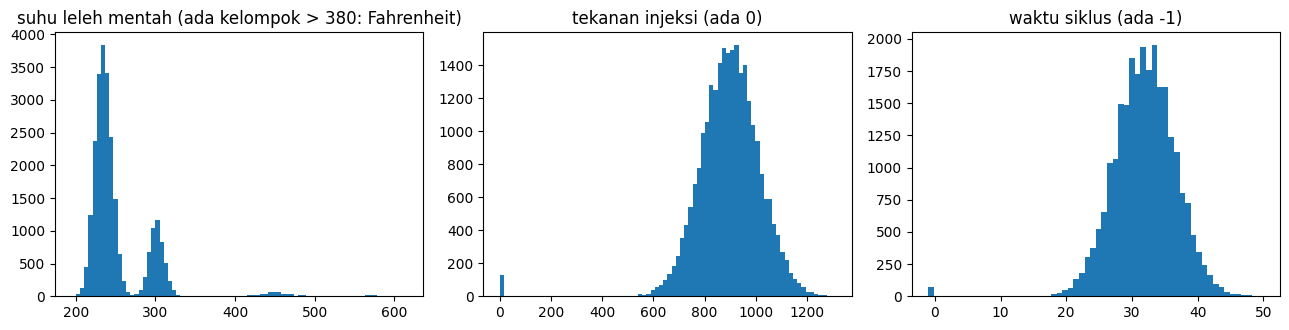

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(raw.suhu_leleh_C, bins=80); ax[0].set_title('suhu leleh mentah (ada kelompok > 380: Fahrenheit)')
ax[1].hist(raw.tekanan_injeksi_bar, bins=80); ax[1].set_title('tekanan injeksi (ada 0)')
ax[2].hist(raw.waktu_siklus_s, bins=60); ax[2].set_title('waktu siklus (ada -1)')
plt.tight_layout(); plt.show()

In [11]:
df = clean(raw)
print(len(df), 'baris bersih; tingkat cacat =', round(df.cacat.mean(), 4))
print(df.groupby('bahan').cacat.mean().round(3).to_dict(), df.groupby('mesin').cacat.mean().round(3).to_dict(), df.groupby('shift').cacat.mean().round(3).to_dict())
print('shift vs jam produksi (proporsi per blok 8 jam):')
print(pd.crosstab(df['shift'], df.waktu_produksi.dt.hour // 8, normalize='index').round(2))

25000 baris bersih; tingkat cacat = 0.0776
{'ABS': 0.118, 'PC': 0.117, 'PP': 0.037} {'IM-01': 0.064, 'IM-02': 0.066, 'IM-03': 0.126, 'IM-04': 0.066} {'malam': 0.1, 'pagi': 0.07, 'siang': 0.07}
shift vs jam produksi (proporsi per blok 8 jam):
waktu_produksi     0     1     2
shift                           
malam           0.33  0.32  0.35
pagi            0.34  0.33  0.33
siang           0.34  0.33  0.33


## 2. EDA: pola yang memengaruhi cacat

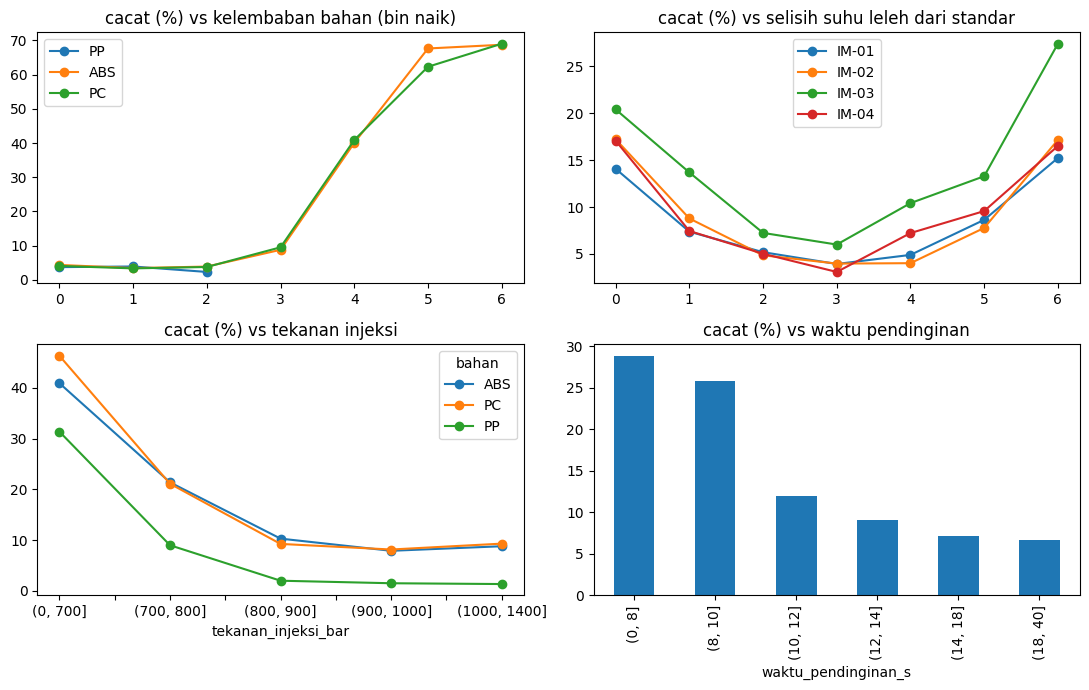

In [12]:
d = feats(df).assign(cacat=df.cacat.values, mesin=df.mesin.values, bahan=df.bahan.values)
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
for b in ['PP','ABS','PC']:
    g = d[d.bahan==b]; r = g.groupby(pd.cut(g.kelembaban_bahan_pct, [-1,.02,.05,.1,.15,.2,.3,1])).cacat.agg(['mean','size']); r = r[r['size']>=30]
    ax[0,0].plot(range(len(r)), r['mean']*100, 'o-', label=b)
ax[0,0].set_title('cacat (%) vs kelembaban bahan (bin naik)'); ax[0,0].legend()
for m in sorted(d.mesin.unique()):
    g = d[d.mesin==m]; r = g.groupby(pd.cut(g.dev_leleh, [-100,-15,-8,-4,4,8,15,100])).cacat.mean()*100
    ax[0,1].plot(range(len(r)), r.values, 'o-', label=m)
ax[0,1].set_title('cacat (%) vs selisih suhu leleh dari standar'); ax[0,1].legend()
r = d[d.tekanan_injeksi_bar.notna()].groupby(['bahan', pd.cut(d.tekanan_injeksi_bar, [0,700,800,900,1000,1400])]).cacat.mean().unstack(0)*100
r.plot(ax=ax[1,0], marker='o', title='cacat (%) vs tekanan injeksi');
d.groupby(pd.cut(d.waktu_pendinginan_s, [0,8,10,12,14,18,40])).cacat.mean().mul(100).plot.bar(ax=ax[1,1], title='cacat (%) vs waktu pendinginan')
plt.tight_layout(); plt.show()

## 3. Pembagian data (stratified 60/20/20)

In [13]:
tr, va, te = T.split(df)
for n, x in [('train', tr), ('validation', va), ('test (belum disentuh)', te)]:
    print(f'{n:24s} n={len(x):6d} cacat={x.cacat.sum():5d} ({x.cacat.mean():.2%})')
ytr, yva = tr.cacat.values, va.cacat.values

train                    n= 15000 cacat= 1164 (7.76%)
validation               n=  5000 cacat=  388 (7.76%)
test (belum disentuh)    n=  5000 cacat=  388 (7.76%)


## 4. *Baseline* wajib: regresi logistik, fitur asli

In [14]:
base = T.make_baseline().fit(tr[RAWCOLS], ytr)
p_base_va = base.predict_proba(va[RAWCOLS])[:, 1]
print('Baseline PR-AUC validation =', round(average_precision_score(yva, p_base_va), 4), '| acuan acak =', round(yva.mean(), 4))

Baseline PR-AUC validation = 0.4833 | acuan acak = 0.0776


## 5. Model lain (dipilih dengan PR-AUC pada *validation*)

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from src.features import ENG_NUM

def lr_fe(C):
    return Pipeline([('f', FunctionTransformer(feats)), ('prep', ColumnTransformer([
        ('n', Pipeline([('i', SimpleImputer(strategy='median', add_indicator=True)), ('s', StandardScaler())]), ENG_NUM),
        ('c', OneHotEncoder(handle_unknown='ignore'), CAT)])), ('m', LogisticRegression(max_iter=5000, C=C))])
res_lr = [(C, average_precision_score(yva, lr_fe(C).fit(tr[RAWCOLS], ytr).predict_proba(va[RAWCOLS])[:,1])) for C in [0.1, 0.3, 1, 3, 10]]
print('LR + fitur turunan (C, PR-AUC val):', [(c, round(s,4)) for c, s in res_lr])

LR + fitur turunan (C, PR-AUC val): [(0.1, np.float64(0.629)), (0.3, np.float64(0.6291)), (1, np.float64(0.6288)), (3, np.float64(0.6291)), (10, np.float64(0.6291))]


In [16]:
grid = list(itertools.product([0.03, 0.06], [8, 15, 31], [20, 60], [0.0, 3.0]))
res = []
for lr_, leaf, msl, l2 in grid:
    T.HGB_PARAMS = dict(learning_rate=lr_, max_leaf_nodes=leaf, min_samples_leaf=msl, l2_regularization=l2)
    m = T.make_final().fit(tr[RAWCOLS], ytr)
    res.append(((lr_, leaf, msl, l2), average_precision_score(yva, m.predict_proba(va[RAWCOLS])[:, 1])))
res.sort(key=lambda x: -x[1])
for k, v in res[:5]: print(k, round(v, 4))
print('terburuk:', round(res[-1][1], 4))

(0.06, 8, 60, 3.0) 0.6489
(0.06, 8, 60, 0.0) 0.6488
(0.03, 8, 20, 3.0) 0.6474
(0.03, 8, 60, 0.0) 0.6472
(0.06, 8, 20, 3.0) 0.6467
terburuk: 0.6208


In [18]:
# model final = kombinasi terbaik di validation (sama dengan T.HGB_PARAMS bawaan di src/train.py)
T.HGB_PARAMS = dict(learning_rate=0.06, max_leaf_nodes=8, min_samples_leaf=60, l2_regularization=3.0)
assert tuple(T.HGB_PARAMS.values()) == res[0][0]
final = T.make_final().fit(tr[RAWCOLS], ytr)
p_va = final.predict_proba(va[RAWCOLS])[:, 1]
print('Model final PR-AUC validation =', round(average_precision_score(yva, p_va), 4))

Model final PR-AUC validation = 0.6489


## 6. *Threshold* dari biaya bisnis

Cacat lolos = Rp500.000, bagus tersisih = Rp25.000, sehingga titik impas teoretis = 25.000 / 525.000 = 4,76%. Pemindaian di *validation*:

threshold optimal di validation = 0.0425 | teori = 0.0476


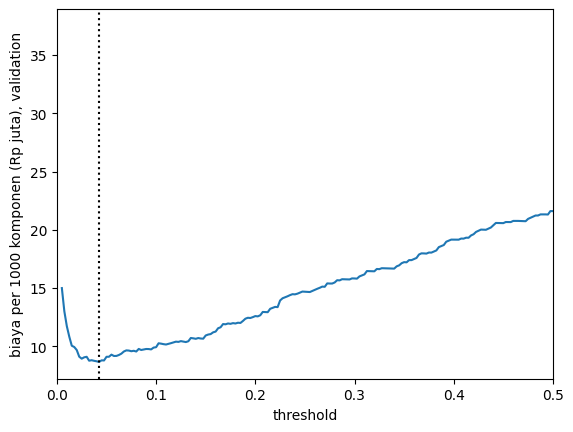

In [19]:
ths = np.round(np.arange(0.005, 0.95, 0.0025), 4)
cv = np.array([T.cost(yva, p_va, t) for t in ths])
thr = float(ths[cv.argmin()])
print('threshold optimal di validation =', thr, '| teori =', round(25000/525000, 4))
plt.plot(ths, cv/len(yva)*1000/1e6); plt.axvline(thr, ls=':', c='k'); plt.xlim(0, .5)
plt.xlabel('threshold'); plt.ylabel('biaya per 1000 komponen (Rp juta), validation'); plt.show()

## 7. Data *test*: dibuka satu kali

In [20]:
yte = te.cacat.values
p_te = final.predict_proba(te[RAWCOLS])[:, 1]; p_te_b = base.predict_proba(te[RAWCOLS])[:, 1]
print('PR-AUC test  baseline =', round(average_precision_score(yte, p_te_b), 4), '| final =', round(average_precision_score(yte, p_te), 4))
def row(name, p, t):
    pred = p >= t; fn = int(((~pred) & (yte==1)).sum()); fp = int((pred & (yte==0)).sum())
    return dict(strategi=name, FN=fn, FP=fp, recall=round(1-fn/yte.sum(), 3), disisihkan=round(pred.mean(), 3), biaya_juta=round((500000*fn+25000*fp)/1e6, 1))
pd.DataFrame([row('loloskan semua', np.zeros(len(yte)), 1), row('sisihkan semua', np.ones(len(yte)), 0),
              row('baseline @4,25%', p_te_b, 0.0425), row(f'final @{thr:.3f}', p_te, thr)])

PR-AUC test  baseline = 0.5364 | final = 0.6977


,strategi,FN,FP,recall,disisihkan,biaya_juta
0,loloskan semua,388,0,0.000,0.000,194.0
1,sisihkan semua,0,4612,1.000,1.000,115.3
2,"baseline @4,25%",42,1563,0.892,0.382,60.1
3,final @0.043,34,915,0.912,0.254,39.9


## 8. Fitur paling berpengaruh (*validation*)

In [21]:
pi = permutation_importance(final, va[RAWCOLS], yva, scoring='average_precision', n_repeats=8, random_state=42)
pd.DataFrame({'fitur': RAWCOLS, 'turun_PR_AUC': pi.importances_mean.round(3)}).sort_values('turun_PR_AUC', ascending=False)

,fitur,turun_PR_AUC
6,kelembaban_bahan_pct,0.384
9,bahan,0.329
2,tekanan_injeksi_bar,0.197
0,suhu_leleh_C,0.178
1,suhu_cetakan_C,0.066
4,waktu_pendinginan_s,0.054
7,mesin,0.022
8,shift,0.012
5,waktu_siklus_s,0.002
3,kecepatan_injeksi_mm_s,0.002


## 9. Simpan model

`src/train.py` mengulang langkah di atas dengan *hyperparameter* terpilih dan menulis `artifacts/model.joblib` serta `artifacts/metadata.json`.

In [24]:
import os

# Ensure we are in /content
os.chdir('/content')

# Create the expected 'data' and 'artifacts' folders
os.makedirs('data', exist_ok=True)
os.makedirs('artifacts', exist_ok=True)

# Copy or symlink raw.csv into the expected data/raw.csv path
if not os.path.exists('data/raw.csv'):
    os.symlink('/content/drive/MyDrive/raw.csv', 'data/raw.csv')

# Run the main function
T.main()

{
 "baseline_pr_val": 0.48325014790960924,
 "baseline_pr_test": 0.5364038754710408,
 "final_pr_val": 0.6488693999440394,
 "final_pr_test": 0.6976625137234945
} threshold: 0.0425
